# CS611 Assignment 1 · Group 8 · Dataset C · 6-bit formats: interactive walkthrough

This notebook is the easiest way to use the submission. It imports the project's own modules
(`formats.py`, `selector.py`, ...) from this folder and computes the main results live, so you
can see every step of the report and change the inputs yourself. It is a companion to the report
(`Report_Group8_DatasetC_6bit.docx`), which has the full explanations; section numbers below refer
to it.

**How to run:** open this file in Jupyter or VS Code from the root of the unzipped submission and
choose *Run All*. Everything below runs in under a minute with only `numpy` and `matplotlib`. The
long studies (about 15 minutes in total) are in the last section and run only if you set
`RUN_LONG = True`.

| Part | What it shows | Report |
|---|---|---|
| 1 | the data | §1.2 |
| 2 | the five candidate formats, and how one block is quantized | §2.1–2.2 |
| 3 | **Q1**: held-out output error of every format | §4 |
| 4 | **Q2**: the chosen selection method against brute force | §6 |
| 5 | **Q3**: outliers, sparsity and variation in scale | §7 |
| 6 | unit tests and regenerating every result | §8 |

In [1]:
import csv, os, subprocess, sys, time
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = os.getcwd()                       # the folder of this notebook = root of the submission
assert os.path.exists(os.path.join(ROOT, "data", "W_C.npy")), "open the notebook from the submission's root folder"
sys.path.insert(0, ROOT)
import formats as F                      # the five quantizers, scale policies, metrics
import selector as S                     # the chosen selection method and every method compared with it
import selector_suite as SUITE           # activation families and test matrices

RUN_LONG = False                         # True: rerun the long studies in part 6 (about 15 minutes)
NPZ = None                               # optional: path to the course file assignment_data.npz (datasets A-E)

SHORT = {"MXFP6_E3M2": "E3M2", "MXFP6_E2M3": "E2M3", "MXFP6_E4M1": "E4M1", "MXINT6": "MXINT6", "BFP6": "BFP6"}
NAMES = list(F.FORMATS)                  # the five candidates


def show(header, rows):
    # Display a list of rows as a table.
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def rel(A, B):
    # Relative Frobenius error in percent, ||A - B|| / ||A||.
    return 100 * np.linalg.norm(A - B) / np.linalg.norm(A)


print("formats.py", F.FORMATS_VERSION, "| candidates:", ", ".join(NAMES))

formats.py v3.0 | candidates: MXFP6_E3M2, MXFP6_E2M3, MXFP6_E4M1, MXINT6, BFP6


## 1. The data (report §1.2)

`W_C` is the 100 × 100 weight matrix and `X_cal` the 100 × 256 calibration input; the layer
computes `Y = W @ X`. As in the report (assumption A11), the even columns of `X_cal` are the
**fit columns** (anything fitted to activations uses only these) and the odd columns are the
**held-out columns** (every reported error is measured on these, standing in for the unseen `X_test`).

In [2]:
W = np.load(os.path.join(ROOT, "data", "W_C.npy")).astype(np.float64)
X = np.load(os.path.join(ROOT, "data", "X_cal.npy")).astype(np.float64)
XF, XE = F.split_X(X)                    # fit (even) and held-out (odd) columns


def kurtosis(a):
    a = a.ravel() - a.mean()
    return float((a ** 4).mean() / (a ** 2).mean() ** 2)


show(["matrix", "shape", "std", "largest |value| / std", "kurtosis (Gaussian: 3)"],
     [["W_C", W.shape, f"{W.std():.3f}", f"{np.abs(W).max() / W.std():.2f}", f"{kurtosis(W):.2f}"],
      ["X_cal", X.shape, f"{X.std():.3f}", f"{np.abs(X).max() / X.std():.2f}", f"{kurtosis(X):.2f}"]])
print("fit columns:", XF.shape, " held-out columns:", XE.shape)

| matrix | shape | std | largest |value| / std | kurtosis (Gaussian: 3) |
|---|---|---|---|---|
| W_C | (100, 100) | 1.000 | 5.70 | 5.76 |
| X_cal | (100, 256) | 0.100 | 4.11 | 3.02 |

fit columns: (100, 128)  held-out columns: (100, 128)


## 2. The five candidate formats (report §2.1–2.2)

Every candidate cuts a row of `W` (and a column of `X`) into blocks of 32 values along the
reduction axis; a row of 100 values has blocks of 32, 32, 32 and a tail of 4. The values of a block
share one power-of-two scale and each value is stored as a 6-bit code. The MX formats store an
8-bit scale; BFP6 (32|4|5) stores a 4-bit exponent in [−8, 7], so it costs fewer bits but has a
limited range.

In [3]:
rows = []
for n in NAMES:
    kind, p, emax = F.spec(n)
    lay = F.layout(n)
    bits = F.quantize(W, n, return_stats=True)[2]["bits_per_elem"]
    grid = (f"FP: {p['ebits']} exponent + {p['mbits']} mantissa bits, vmax {p['maxval']:g}" if kind == "fp"
            else "integer: sign + 5-bit magnitude" if kind == "bfp" else "integer: two's complement [-32, 31] x 2^-4")
    rows.append([n, grid, lay["block"], f"{lay['scale_bits']}-bit", f"{bits:.2f}"])
show(["format", "element grid", "block", "shared scale", "bits/element"], rows)

| format | element grid | block | shared scale | bits/element |
|---|---|---|---|---|
| MXFP6_E3M2 | FP: 3 exponent + 2 mantissa bits, vmax 28 | 32 | 8-bit | 6.32 |
| MXFP6_E2M3 | FP: 2 exponent + 3 mantissa bits, vmax 7.5 | 32 | 8-bit | 6.32 |
| MXFP6_E4M1 | FP: 4 exponent + 1 mantissa bits, vmax 384 | 32 | 8-bit | 6.32 |
| MXINT6 | integer: two's complement [-32, 31] x 2^-4 | 32 | 8-bit | 6.32 |
| BFP6 | integer: sign + 5-bit magnitude | 32 | 4-bit | 6.16 |

**One block, step by step.** The cell below quantizes the first block of row 0 of `W_C` with each
format under the class rule (`ocp`): the shared exponent puts the block maximum in the top binade of
the grid, every value is divided by the scale, rounded to the nearest grid point (ties to even) and
multiplied back. Small values are where the formats differ most: the integer grids have a fixed step
set by the block maximum, so they flush more small values to zero; E2M3 keeps them on a finer grid.

In [4]:
blk = W[:1, :32]
order = np.argsort(np.abs(blk[0]))       # smallest to largest magnitude
pick = np.r_[order[:4], order[-4:]]      # the 4 smallest and the 4 largest values of the block
fmt = lambda v: "0" if v == 0 else f"{v:+.4f}"      # noqa: E731
rows = [["original"] + [fmt(v) for v in blk[0, pick]]]
for n in NAMES:
    q, e, st = F.quantize(blk, n, return_stats=True)
    rows.append([f"{SHORT[n]} (exp {int(e[0, 0])}, {st['n_zeroed']} of 32 flushed)"] + [fmt(v) for v in q[0, pick]])
show([""] + [f"small {i}" for i in range(1, 5)] + [f"large {i}" for i in range(1, 5)], rows)

|  | small 1 | small 2 | small 3 | small 4 | large 1 | large 2 | large 3 | large 4 |
|---|---|---|---|---|---|---|---|---|
| original | -0.0277 | +0.0556 | -0.1318 | +0.1548 | -1.3524 | -1.6740 | -2.1176 | +2.1338 |
| E3M2 (exp -3, 0 of 32 flushed) | -0.0312 | +0.0547 | -0.1250 | +0.1562 | -1.2500 | -1.7500 | -2.0000 | +2.0000 |
| E2M3 (exp -1, 1 of 32 flushed) | 0 | +0.0625 | -0.1250 | +0.1250 | -1.3750 | -1.6250 | -2.0000 | +2.2500 |
| E4M1 (exp -7, 0 of 32 flushed) | -0.0312 | +0.0625 | -0.1250 | +0.1250 | -1.5000 | -1.5000 | -2.0000 | +2.0000 |
| MXINT6 (exp 1, 2 of 32 flushed) | 0 | 0 | -0.1250 | +0.1250 | -1.3750 | -1.6250 | -2.1250 | +2.1250 |
| BFP6 (exp 1, 2 of 32 flushed) | 0 | 0 | -0.1250 | +0.1250 | -1.3750 | -1.6250 | -2.1250 | +2.1250 |

## 3. Q1: which format is most suitable for `W_C`? (report §4)

The primary setting quantizes **both W and X** with the candidate (X in blocks down its columns)
and measures the relative error of the layer output on the held-out columns:
`e_Y = ||W X − Wq Xq|| / ||W X||`. The weights-only setting keeps X exact. `ocp` is the class scale
rule; `opt` searches the shared exponent per block (`e_ocp + {−2, −1, 0, +1}`).

In [5]:
Y = W @ XE
res = {}
for n in NAMES:
    for pol in ("ocp", "opt"):
        Wq = F.quantize(W, n, policy=pol)[0]
        Xq = F.quantize_X(XE, n, policy=pol)[0]
        res[n, pol, "wx"] = rel(Y, Wq @ Xq)      # W and X quantized (primary)
        res[n, pol, "w"] = rel(Y, Wq @ XE)       # weights only
rank = sorted(NAMES, key=lambda n: res[n, "ocp", "wx"])
show(["format", "W+X, class rule (%)", "W+X, opt (%)", "weights only, class rule (%)", "weights only, opt (%)"],
     [[("**" + n + "**") if n == rank[0] else n] + [f"{res[n, p, m]:.3f}" for m in ("wx", "w") for p in ("ocp", "opt")]
      for n in rank])
print(f"best: {rank[0]}, {res[rank[1], 'ocp', 'wx'] - res[rank[0], 'ocp', 'wx']:.3f} pp ahead of {rank[1]} (W+X, class rule)")

# the same numbers as the report's Table 5 (results/tables/T1_main_C.csv)
T1 = {r["format"]: r for r in csv.DictReader(open(os.path.join(ROOT, "results", "tables", "T1_main_C.csv")))}
assert all(abs(res[n, "ocp", "wx"] - float(T1[n]["W+X held-out Y err % (ocp)"])) < 1e-6 for n in NAMES)
print("matches results/tables/T1_main_C.csv")

| format | W+X, class rule (%) | W+X, opt (%) | weights only, class rule (%) | weights only, opt (%) |
|---|---|---|---|---|
| **MXFP6_E2M3** | 4.244 | 4.211 | 3.101 | 3.076 |
| MXINT6 | 5.213 | 4.973 | 4.054 | 3.880 |
| BFP6 | 5.218 | 5.047 | 4.054 | 3.938 |
| MXFP6_E3M2 | 7.695 | 7.412 | 5.469 | 5.257 |
| MXFP6_E4M1 | 15.932 | 14.583 | 11.149 | 10.237 |

best: MXFP6_E2M3, 0.969 pp ahead of MXINT6 (W+X, class rule)
matches results/tables/T1_main_C.csv


**Why E2M3 wins (report §4.2).** The output error splits into a weight term and an activation term
(next part). The cell below shows, per format, the share of the weights flushed to zero and the
error of each operand on its own (X on the held-out columns): E2M3 keeps the small weights, and its
weight error is much smaller than that of the integer grids; on `X_cal` (Gaussian, small range) E2M3
and the integer grids are much closer.

In [6]:
rows = []
for n in rank:
    Wq, _, st = F.quantize(W, n, return_stats=True)
    rows.append([n, st["n_zeroed"], st["n_range"], f"{rel(W, Wq):.3f}", f"{rel(XE, F.quantize_X(XE, n)[0]):.3f}"])
show(["format", "weights flushed to 0 (of 10,000)", "weights above the grid's range", "W error (%)",
      "X error, held-out columns (%)"], rows)

| format | weights flushed to 0 (of 10,000) | weights above the grid's range | W error (%) | X error, held-out columns (%) |
|---|---|---|---|---|
| MXFP6_E2M3 | 461 | 43 | 3.082 | 2.867 |
| MXINT6 | 891 | 15 | 4.025 | 3.196 |
| BFP6 | 891 | 20 | 4.025 | 3.201 |
| MXFP6_E3M2 | 66 | 96 | 5.421 | 5.489 |
| MXFP6_E4M1 | 1 | 245 | 11.051 | 11.175 |

## 4. Q2: the chosen selection method (report §6)

`selector.select_format(W, X_cal)` is the chosen method, the **exact activation-weighted sketch**.
It approximates the squared output error by two terms,
`||W X − Wq Xq||² ≈ ||ΔW X||² + ||W ΔX||²`, keeps the diagonal of `H = X Xᵀ`, and computes each term
for all five formats from one pass over the data, **without quantizing anything**: it sorts the
values into bins by their position relative to their block maximum and adds up three sums per bin;
a small table per format turns the sums into that format's error.

Below it is compared with brute force that quantizes with every format and measures the same
objective, and with the true held-out error from part 3.

In [7]:
def timed(fn, reps=7):
    # Median wall time in seconds of fn() over reps calls, and its last result.
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        out = fn()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out


h = (XF ** 2).sum(1)                                # energy of each input channel (weights the weight term)
g = (W ** 2).sum(0)                                 # energy of each column of W (weights the activation term)


def brute_force():                                  # quantize W and X with all five formats
    ew, ex = S.exhaustive(W, h), S.exhaustive(XF.T, g)
    return {n: ew[n] + ex[n] for n in NAMES}


S.select_format(W, XF)                              # first call builds the per-format tables once
t_method, (best, scores) = timed(lambda: S.select_format(W, XF))   # fit columns only
t_brute, brute = timed(brute_force)

show(["format", "chosen method: score", "brute force, same objective", "relative difference", "held-out e_Y (%)"],
     [[n, f"{scores[n]:.6g}", f"{brute[n]:.6g}", f"{abs(scores[n] - brute[n]) / brute[n]:.1e}", f"{res[n, 'ocp', 'wx']:.3f}"]
      for n in sorted(NAMES, key=scores.get)])
print(f"chosen method picks {best} in {1000 * t_method:.2f} ms (brute force {1000 * t_brute:.2f} ms, median of 7); "
      f"held-out winner: {rank[0]}")
print("weights-only mode picks", S.select_format(W, XF, mode="w")[0])

| format | chosen method: score | brute force, same objective | relative difference | held-out e_Y (%) |
|---|---|---|---|---|
| MXFP6_E2M3 | 22.5354 | 22.5354 | 1.3e-15 | 4.244 |
| MXINT6 | 33.0818 | 33.0818 | 1.0e-14 | 5.213 |
| BFP6 | 33.1058 | 33.1058 | 1.0e-14 | 5.218 |
| MXFP6_E3M2 | 75.4231 | 75.4231 | 3.4e-15 | 7.695 |
| MXFP6_E4M1 | 317.085 | 317.085 | 9.0e-16 | 15.932 |

chosen method picks MXFP6_E2M3 in 1.07 ms (brute force 3.09 ms, median of 7); held-out winner: MXFP6_E2M3
weights-only mode picks MXFP6_E2M3


**Try it on other data.** Change the distribution of `W2` or the activation family below. Families
(report §2.6): `white`, `chan_gain`, `outlier_chan`, `lowrank`, `heavy_t3`, `ar1`, `relu`, `massive`,
`sparse_act`. The cell compares the method's pick with the held-out winner found by quantizing.

In [8]:
rng = np.random.default_rng(0)
W2 = rng.laplace(size=(100, 100))                   # try rng.standard_normal, rng.standard_t(3, ...), ...
X2 = SUITE._x(rng, 100, "massive")                 # 100 input channels x 256 columns
X2f, X2e = F.split_X(X2)
pick, _ = S.select_format(W2, X2f)
truth = {n: rel(W2 @ X2e, F.quantize(W2, n)[0] @ F.quantize_X(X2e, n)[0]) for n in NAMES}
show(["format", "held-out e_Y (%)"], [[("**" + n + "**") if n == pick else n, f"{truth[n]:.3f}"]
                                      for n in sorted(NAMES, key=truth.get)])
print("method picks", pick, "| held-out winner", min(truth, key=truth.get))

| format | held-out e_Y (%) |
|---|---|
| **MXFP6_E2M3** | 5.201 |
| MXINT6 | 5.486 |
| BFP6 | 6.316 |
| MXFP6_E3M2 | 7.995 |
| MXFP6_E4M1 | 19.337 |

method picks MXFP6_E2M3 | held-out winner MXFP6_E2M3


**The full benchmark (saved results).** On 1000 random test matrices with 9 activation families,
the chosen method makes exactly the same pick as brute force with the same objective. Its top-1
agreement with the held-out winner is below 100% for every method, brute force included, because
all of them choose on the fit columns while the truth is measured on the held-out columns
(report §6.4). Rerun with `python bench_selector.py` (part 6).

| method | matrices | top-1 agreement | mean regret (dB) | median ms |
|---|---|---|---|---|
| chosen method (exact sketch) | 1000 | 86.0% | 0.054 | 1.92 |
| brute force, same objective | 1000 | 86.0% | 0.054 | 4.47 |
| brute force, full output | 1000 | 86.2% | 0.042 | 12.30 |
| brute force, no activation weighting | 1000 | 68.5% | 1.110 | 4.39 |

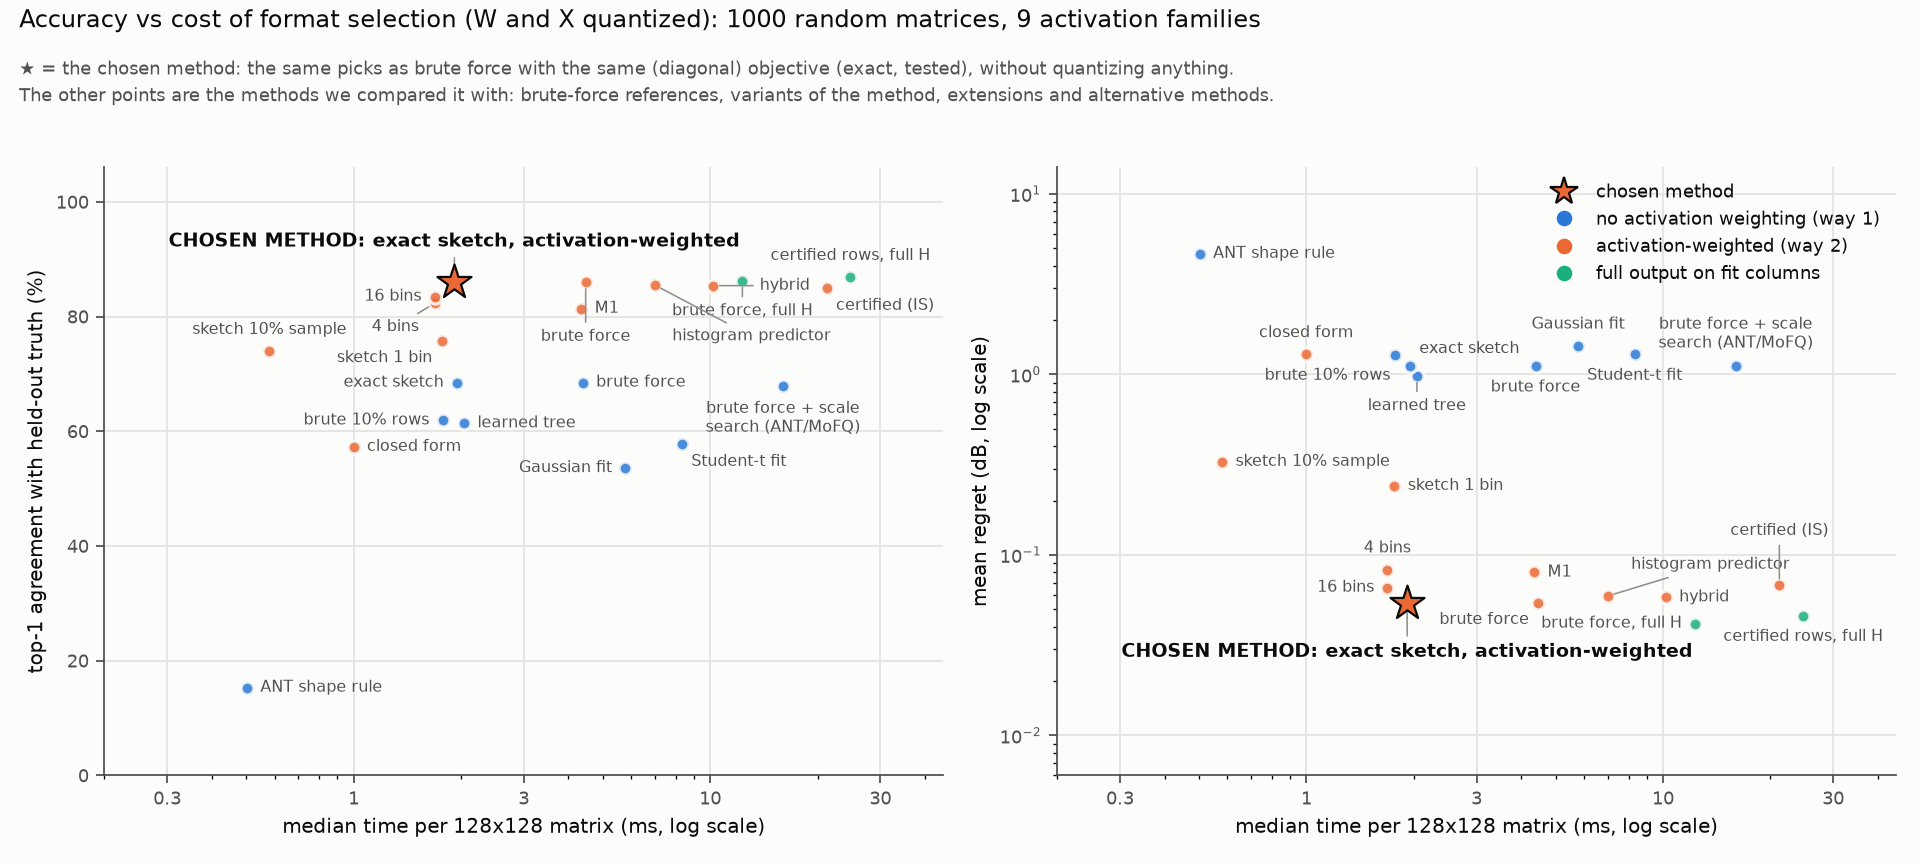

In [9]:
B = [r for r in csv.DictReader(open(os.path.join(ROOT, "results", "selector_bench_wx.csv"))) if r["suite"] == "random"]
rows = []
for a, label in ((S.METHOD, "chosen method (exact sketch)"), ("exhaustive_h", "brute force, same objective"),
                 ("exhaustive_y", "brute force, full output"), ("exhaustive_w", "brute force, no activation weighting")):
    R = [r for r in B if r["approach"] == a]
    rows.append([label, len(R), f"{100 * np.mean([int(r['hit']) for r in R]):.1f}%",
                 f"{np.mean([float(r['regret_y_db']) for r in R]):.3f}", f"{1000 * np.median([float(r['seconds']) for r in R]):.2f}"])
show(["method", "matrices", "top-1 agreement", "mean regret (dB)", "median ms"], rows)
display(Image(os.path.join(ROOT, "figures", "fig6_selector_accuracy_vs_cost.png"), width=900))

## 5. Q3: outliers, sparsity and variation in scale (report §7)

Each line below modifies `W_C` once (one random seed) and recomputes the held-out W+X error of every
format and the chosen method's pick. The report averages 10 seeds per setting (`q3_study.py`), so
near a crossover (for example 85% zeros, where the report finds MXINT6 ahead by 0.06 pp on average)
a single seed can go either way. The saved 10-seed figures follow.

In [10]:
def evaluate(Wm):
    e = {n: rel(Wm @ XE, F.quantize(Wm, n)[0] @ F.quantize_X(XE, n)[0]) for n in NAMES}
    return e, S.select_format(Wm, XF)[0]


rng = np.random.default_rng(1)
cases = {}
for nout, k in ((100, 20), (100, 100)):              # n outliers of about k standard deviations
    Wm = W.copy()
    idx = rng.choice(W.size, nout, replace=False)
    Wm.flat[idx] = rng.choice([-1, 1], nout) * k * W.std() * rng.uniform(0.7, 1.3, nout)
    cases[f"{nout} outliers of {k}σ"] = Wm
for p in (50, 85):                                    # a share p of the weights set to zero
    cases[f"{p}% zeros"] = W * (rng.random(W.shape) >= p / 100)
cases["row gains 10^±2"] = W * 10 ** rng.uniform(-2, 2, (100, 1))   # one gain per output row
rows = []
for name, Wm in cases.items():
    e, pick = evaluate(Wm)
    win = min(e, key=e.get)
    rows.append([name] + [f"{e[n]:.2f}" for n in NAMES] + [SHORT[win], SHORT[pick]])
show(["W_C modified by"] + [SHORT[n] for n in NAMES] + ["held-out winner", "method picks"], rows)

| W_C modified by | E3M2 | E2M3 | E4M1 | MXINT6 | BFP6 | held-out winner | method picks |
|---|---|---|---|---|---|---|---|
| 100 outliers of 20σ | 7.72 | 4.95 | 15.50 | 7.09 | 7.09 | E2M3 | E2M3 |
| 100 outliers of 100σ | 8.69 | 4.70 | 19.58 | 5.29 | 5.31 | E2M3 | E2M3 |
| 50% zeros | 7.73 | 4.18 | 16.10 | 4.75 | 4.75 | E2M3 | E2M3 |
| 85% zeros | 7.90 | 4.05 | 16.57 | 4.08 | 4.09 | E2M3 | E2M3 |
| row gains 10^±2 | 7.33 | 4.08 | 15.55 | 4.98 | 6.56 | E2M3 | E2M3 |

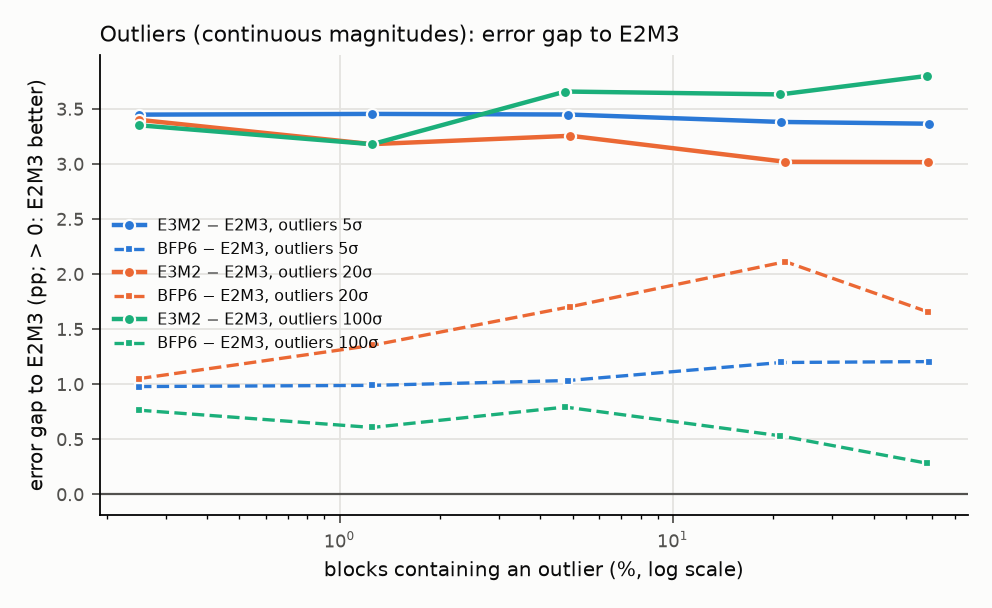

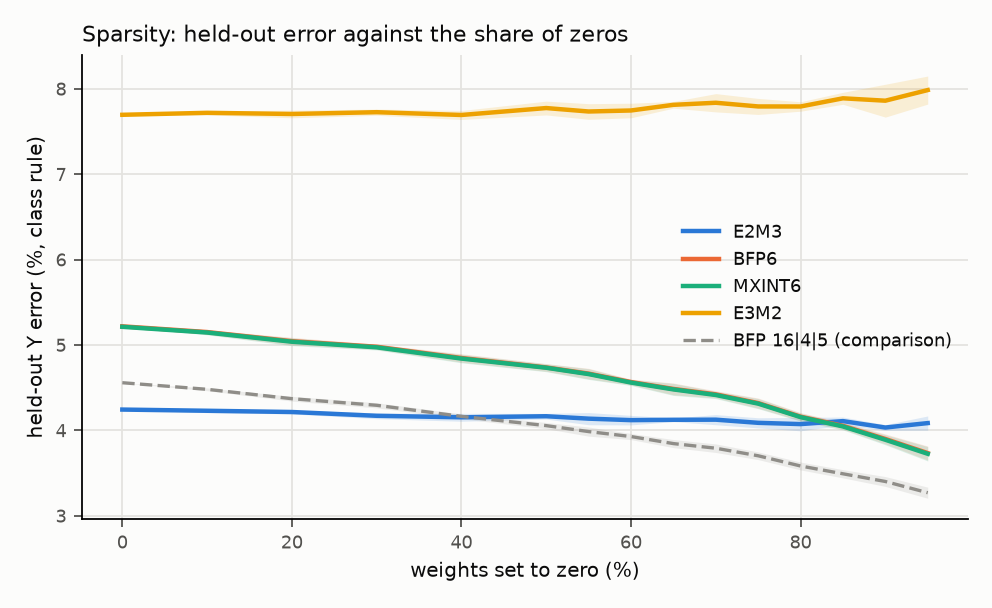

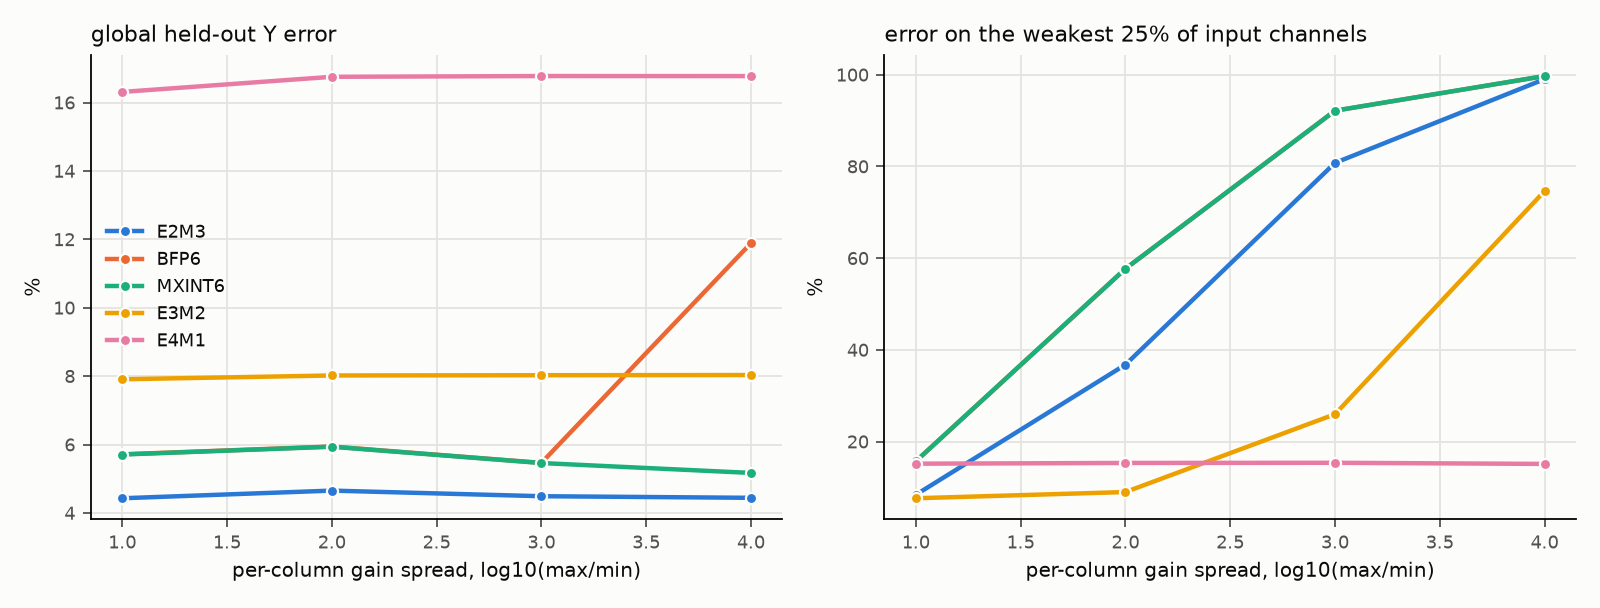

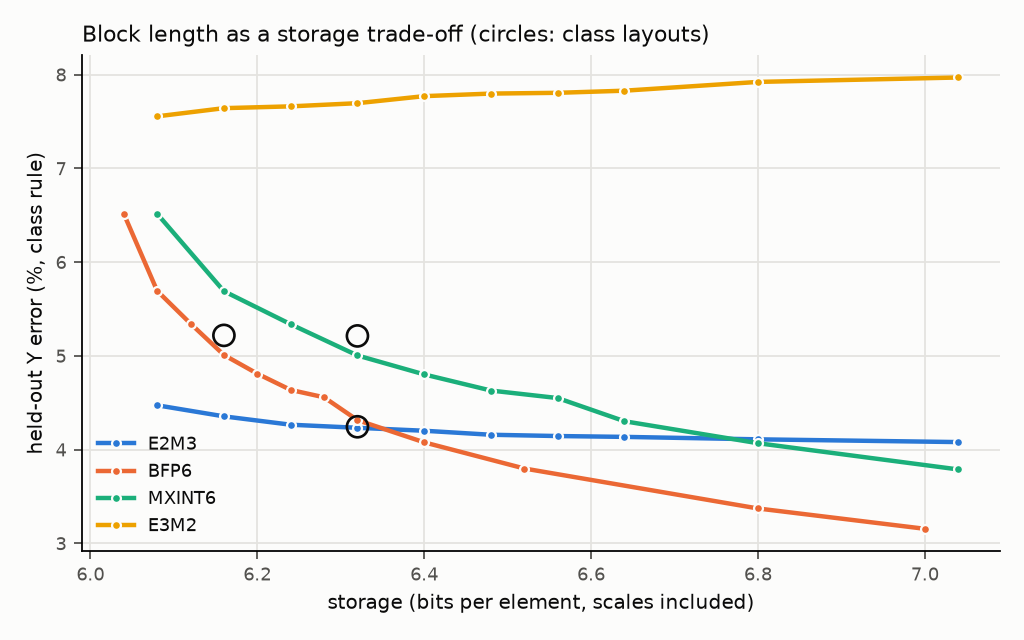

In [11]:
for f in ("fig8_q3_outliers.png", "fig9_q3_sparsity.png", "fig10_q3_scale.png", "fig11_block_tradeoff.png"):
    display(Image(os.path.join(ROOT, "figures", f), width=760))

## 6. Unit tests and regenerating every result (report §8)

The unit tests take a few seconds. The studies regenerate the files in `results/` and `figures/`
that the report reads; `report/build_report.py` then rebuilds the report from them (it needs
`python-docx`). Datasets A–E (context only) need the course file `assignment_data.npz`: set `NPZ`
in the first code cell.

In [12]:
for t in ("test_formats.py", "test_selector.py", "test_scale_opt.py", os.path.join("verification", "test_reference_impl.py")):
    r = subprocess.run([sys.executable, t], cwd=ROOT, capture_output=True, text=True)
    print(f"{t:40s}", (r.stdout.strip().splitlines() or ["(no output)"])[-1], "" if r.returncode == 0 else "FAILED")

test_formats.py                          31/31 passed 


test_selector.py                         13/13 passed 


test_scale_opt.py                        16/16 passed 
verification/test_reference_impl.py      all 17 tests passed 


In [13]:
npz = ["--npz", NPZ] if NPZ else []
STUDIES = [["run_all.py"] + npz,                                    # tables T1-T9, baselines, figures (~30 s)
           ["bench_selector.py"] + npz, ["bench_selector.py", "--mode", "w"] + npz,   # Q2 benchmark (~5 min each)
           ["bench_scaling.py"],                                   # Q2 cost against matrix size
           ["x_stress.py"] + npz,                                  # 11 activation families
           ["q3_study.py"], ["q3_study.py", "--mode", "w"],        # Q3 (~2 min each)
           ["block_study.py"] + npz, ["block_study.py", "--mode", "w"] + npz,
           ["make_selector_figures.py"],
           [os.path.join("report", "build_report.py")]]            # the report, from results/
for cmd in STUDIES:
    if not RUN_LONG:
        print("python", " ".join(cmd))
        continue
    t0 = time.perf_counter()
    r = subprocess.run([sys.executable] + cmd, cwd=ROOT, capture_output=True, text=True)
    print(f"{' '.join(cmd):45s} {time.perf_counter() - t0:6.0f} s", "ok" if r.returncode == 0 else "FAILED\n" + r.stderr[-2000:])
if not RUN_LONG:
    print("\n(set RUN_LONG = True in the first code cell to run these here)")

python run_all.py
python bench_selector.py
python bench_selector.py --mode w
python bench_scaling.py
python x_stress.py
python q3_study.py
python q3_study.py --mode w
python block_study.py
python block_study.py --mode w
python make_selector_figures.py
python report/build_report.py

(set RUN_LONG = True in the first code cell to run these here)
